<a href="https://colab.research.google.com/github/tanishjain-tmj/Risk-alert-Classifier-ML-Regression-project/blob/main/Risk_alert_Classifier_ML_Regression_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Risk alert Classifier ML-Regression-project:

#Part A-Conceptual Understanding(Theory):


1. What is Logistic Regression and why is it suitable for classification?

Ans. Logistic Regression is a supervised machine learning algorithm used for classification. It predicts the probability of a class using the sigmoid function and is suitable for binary classification problems.


2. Explain classification performance metrics and why accuracy alone is insufficient.

Ans. Classification metrics measure model performance using Accuracy, Precision, Recall and F1-score. Accuracy alone can be misleading, especially when the dataset is imbalanced.

3. Define Type-I Error and Type-II Error in the context of risk prediction.

Ans. a. Type-I Error (False Positive): A low-risk customer is incorrectly predicted as high-risk.
b. Type-II Error (False Negative): A high-risk customer is incorrectly predicted as low-risk.

4. Explain Precision, Recall, F1-Score, TPR, and FPR.

Ans.
 - Precision: Correct high-risk predictions out of all predicted high-risk customers.
- Recall: Correctly identified high-risk customers out of all actual high-risk customers.
- F1-Score: Harmonic mean of Precision and Recall.
- TPR: Same as Recall; measures correctly identified positive cases.
- FPR: Measures the proportion of actual negative cases incorrectly predicted as positive.

5. What is AUC-ROC and how does it help in evaluating classifiers?

Ans. AUC-ROC measures how effectively a classifier distinguishes between different classes. A higher AUC score indicates better classification performance, while 0.5 represents random classification.

6. Why does imbalanced data create problems in classification models?

Ans. Imbalanced data occurs when one class has significantly more samples than another. It can make models biased toward the majority class, resulting in poor minority-class predictions and misleading accuracy.

#Part B- Dataset understanding and preparation:

In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv('/content/Risk_Alert_Classifier_Dataset_4600 - Risk_Alert_Classifier_Dataset_4600.csv.csv')
df.head(5)

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [3]:
df.shape

(4600, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
#Input features anfd target variable:
x= df.drop(columns=['risk_status','last_transaction_date','customer_id'],axis=1)
y= df['risk_status']
print("Input Features:",x.columns.tolist())
print("\nTarget Variable:",y.name)

Input Features: ['age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr']

Target Variable: risk_status


In [7]:
#train-test split:
from sklearn.model_selection import train_test_split
x_train,x_test, y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)
print("x_train shape",x_train.shape)
print("x_test shape",x_test.shape)
print("y_train shape",y_train.shape)
print("y_test shape",y_test.shape)

x_train shape (3680, 16)
x_test shape (920, 16)
y_train shape (3680,)
y_test shape (920,)


In [8]:
#missing values:
x.isnull().sum()

,0
age,140
gender,0
region,102
employment_type,144
annual_income_inr,166
credit_score,216
credit_utilization_ratio,147
missed_payments_12m,0
avg_late_payment_days,0
monthly_transaction_count,0


In [9]:
y.isnull().sum()

np.int64(0)

In [10]:
#missing value imputation, encoding , scaling :
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [11]:
num_cols= x_train.select_dtypes(include=['number']).columns
cat_cols= x_train.select_dtypes(include=['object','category']).columns

In [12]:
#numerical pipeline(knn imputation + scaling):
num_pipeline= Pipeline([('imputer',KNNImputer(n_neighbors=5)),
                        ('scaler',StandardScaler())])

In [13]:
#categorical pipeline(simple imputation + encoding):
cat_pipeline= Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                        ('encoder',OneHotEncoder(handle_unknown='ignore'))])

In [14]:
preprocessor= ColumnTransformer([('num',num_pipeline,num_cols),
                                 ('cat',cat_pipeline,cat_cols)])

In [15]:
x_trainf= preprocessor.fit_transform(x_train)
x_testf= preprocessor.transform(x_test)

In [16]:
np.isnan(x_trainf).sum()

np.int64(0)

In [17]:
np.isnan(x_testf).sum()

np.int64(0)

Therefore missing values are imputated.

#Part C - Baseline Classification model:

In [18]:
#Logistic regression:
from sklearn.linear_model import LogisticRegression

In [19]:
lr_model= LogisticRegression(random_state=42)
lr_model.fit(x_trainf,y_train)

LogisticRegression(random_state=42)

In [20]:
y_pred= lr_model.predict(x_testf)

In [21]:
comparison_df= pd.DataFrame({'Actual':y_test,'Prediction':y_pred})

In [22]:
print("comparsion of atual and predicted:\n",comparison_df)

comparsion of atual and predicted:
       Actual  Prediction
3683       0           0
4411       0           0
2584       0           0
69         0           0
1844       0           0
...      ...         ...
1612       1           1
1068       0           0
4350       0           0
3027       0           0
3455       0           0

[920 rows x 2 columns]


In [23]:
from sklearn.metrics import r2_score
r2= r2_score(y_test,y_pred)
print("r2 score of lr_model:",r2)

r2 score of lr_model: 0.9906792024639326


In [24]:
#confusion, accuracy,precision,recall,f1_score:
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,f1_score)

cm= confusion_matrix(y_test,y_pred)
acc= accuracy_score(y_test,y_pred)
pre= precision_score(y_test,y_pred)
recall= recall_score(y_test,y_pred)
f1= f1_score(y_test,y_pred)

print("Confusion matrix:",cm)
print("Accuracy:",acc)
print("Precision:",pre)
print("Recall:",recall)
print("F1-score:",f1)

Confusion matrix: [[795   1]
 [  0 124]]
Accuracy: 0.9989130434782608
Precision: 0.992
Recall: 1.0
F1-score: 0.9959839357429718


In [25]:
#type 1, type 2 error:
tn,fp,fn,tp = cm.ravel()
print("Type-I error:",fp)
print("Type-II error:",fn)

Type-I error: 1
Type-II error: 0


#Part D: Handling imbalanced data:

In [26]:
#checking data :
print(y_train.value_counts())

risk_status
0    3247
1     433
Name: count, dtype: int64


hence the data is imbalanced

In [27]:
#undersampling:
from imblearn.under_sampling import RandomUnderSampler
under= RandomUnderSampler(random_state=42)
x_under,y_under= under.fit_resample(x_trainf,y_train)
print(y_under.value_counts())

model_under= LogisticRegression(random_state=42)
model_under.fit(x_under,y_under)
y_pred_under= model_under.predict(x_testf)
r2_under= r2_score(y_test,y_pred_under)
print("R2 score of undersampling model:",r2_under)

risk_status
0    433
1    433
Name: count, dtype: int64
R2 score of undersampling model: 0.8974712271032582


In [28]:
#over sampling:
from imblearn.over_sampling import RandomOverSampler
over= RandomOverSampler(random_state=42)
x_over,y_over= over.fit_resample(x_trainf,y_train)

model_over= LogisticRegression(random_state=42)
model_over.fit(x_over,y_over)
y_pred_over= model_over.predict(x_testf)
r2_over= r2_score(y_test,y_pred_over)
print("R2 score of oversampling model:",r2_over)

R2 score of oversampling model: 0.9161128221753931


In [29]:
#SMOTE:
from imblearn.over_sampling import SMOTE
smote= SMOTE(random_state=42)
x_smote,y_smote= smote.fit_resample(x_trainf,y_train)

model_smote= LogisticRegression(random_state=42)
model_smote.fit(x_smote,y_smote)
y_pred_smote= model_smote.predict(x_testf)
r2_smote= r2_score(y_test,y_pred_smote)
print("R2 score of smote model:",r2_smote)

R2 score of smote model: 0.9533960123196629


In [30]:
#ADASYN:
from imblearn.over_sampling import ADASYN
ada= ADASYN(random_state=42)
x_ada,y_ada= ada.fit_resample(x_trainf,y_train)

model_ada= LogisticRegression(random_state=42)
model_ada.fit(x_ada,y_ada)
y_pred_ada= model_ada.predict(x_testf)
r2_ada= r2_score(y_test,y_pred_ada)
print("R2 score of ADASYN model:",r2_ada)

R2 score of ADASYN model: 0.8974712271032582


In [31]:
from sklearn.metrics import roc_auc_score
print("Original model:")
print("recall:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))
print("auc-roc:",roc_auc_score(y_test,lr_model.predict_proba(x_testf)[:,1]))

print("\nUnder sampling:")
print("recall:",recall_score(y_test,y_pred_under))
print("f1_score:",f1_score(y_test,y_pred_under))
print("auc-roc:",roc_auc_score(y_test,model_under.predict_proba(x_testf)[:,1]))

print("\nOver sampling:")
print("recall:",recall_score(y_test,y_pred_over))
print("f1_score:",f1_score(y_test,y_pred_over))
print("auc-roc:",roc_auc_score(y_test,model_over.predict_proba(x_testf)[:,1]))

print("\nSMOTE:")
print("recall:",recall_score(y_test,y_pred_smote))
print("f1_score:",f1_score(y_test,y_pred_smote))
print("auc-roc:",roc_auc_score(y_test,model_smote.predict_proba(x_testf)[:,1]))

print("\nADASYN:")
print("recall:",recall_score(y_test,y_pred_ada))
print("f1_score:",f1_score(y_test,y_pred_ada))
print("auc-roc:",roc_auc_score(y_test,model_ada.predict_proba(x_testf)[:,1]))

Original model:
recall: 1.0
f1_score: 0.9959839357429718
auc-roc: 0.9999898686983304

Under sampling:
recall: 1.0
f1_score: 0.9575289575289575
auc-roc: 0.9999696060949911

Over sampling:
recall: 1.0
f1_score: 0.9649805447470817
auc-roc: 0.9999898686983304

SMOTE:
recall: 1.0
f1_score: 0.9802371541501976
auc-roc: 0.9999797373966608

ADASYN:
recall: 1.0
f1_score: 0.9575289575289575
auc-roc: 0.9999797373966608


#Part E - Tree based classification model

In [32]:
#Decision tree clasifier:
from sklearn.tree import DecisionTreeClassifier
dt_model= DecisionTreeClassifier(random_state=42)
dt_model.fit(x_trainf,y_train)

DecisionTreeClassifier(random_state=42)

In [33]:
#training pred
y_train_pred_dt=dt_model.predict(x_trainf)
#testing pred
y_test_pred_dt=dt_model.predict(x_testf)

In [34]:
print("Training R2 Score:", r2_score(y_train, y_train_pred_dt))
print("Testing R2 Score:", r2_score(y_test, y_test_pred_dt))

Training R2 Score: 1.0
Testing R2 Score: 0.7017344788458421


In [35]:
#comparing training and testing performance:
dt_train_acc= accuracy_score(y_train,y_train_pred_dt)
dt_test_acc= accuracy_score(y_test,y_test_pred_dt)
print("Training accuracy:",dt_train_acc)
print("Testing axxuracy:",dt_test_acc)

if dt_train_acc >= dt_test_acc :
  print("overfitting")
else:
  print("general")

Training accuracy: 1.0
Testing axxuracy: 0.9652173913043478
overfitting


In [36]:
#Random Forest Classifier:
from sklearn.ensemble import RandomForestClassifier
rf_model= RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(x_trainf,y_train)

RandomForestClassifier(random_state=42)

In [37]:
y_pred_rf= rf_model.predict(x_testf)
r2_rf= r2_score(y_test,y_pred_ada)
print("R2 score of random forest model:",r2_rf)

R2 score of random forest model: 0.8974712271032582


In [38]:
#training pred
y_train_pred_rf=rf_model.predict(x_trainf)
#testing pred
y_test_pred_rf=rf_model.predict(x_testf)

In [39]:
rf_train_acc= accuracy_score(y_train,y_train_pred_rf)
rf_test_acc= accuracy_score(y_test,y_test_pred_rf)
print("Training accuracy:",rf_train_acc)
print("Testing axxuracy:",rf_test_acc)

Training accuracy: 1.0
Testing axxuracy: 0.991304347826087


In [40]:
#comparing decison tree and random forest:
#accuracy:

comparison= pd.DataFrame({'model':['Decision tree','random forest'],
                          'Training Accuracy':[dt_train_acc,rf_train_acc],
                          'testing accuracy':[dt_test_acc,rf_test_acc]})
print("accuracy comparison of decision tree and random forest:\n",comparison)


accuracy comparison of decision tree and random forest:
            model  Training Accuracy  testing accuracy
0  Decision tree                1.0          0.965217
1  random forest                1.0          0.991304


#part F- HyperParameter tuning:

In [41]:
#random search for decision tree:
from sklearn.model_selection import RandomizedSearchCV
dt_params= {'max_depth':[None,3,5,7,10,15,20],
            'min_samples_split':[2,5,10,20],
            'min_samples_leaf':[1,2,4,8],
            'criterion':['gini','entropy']}
dt_random= RandomizedSearchCV(DecisionTreeClassifier(random_state=42),param_distributions=dt_params,n_iter=20,cv=5,scoring='recall',n_jobs=-1,random_state=42)
dt_random.fit(x_trainf,y_train)
print("best Decision tree parameters:",dt_random.best_params_)
print("best Cv recall score:", dt_random.best_score_)


best Decision tree parameters: {'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 15, 'criterion': 'gini'}
best Cv recall score: 0.8846030473135527


In [42]:
#random search for random forest:
from sklearn.model_selection import RandomizedSearchCV
rf_params= {'n_estimators':[100,200,300,500],
            'max_depth':[None,5,10,15,20],
            'min_samples_split':[2,5,10],
            'min_samples_leaf':[1,2,4],
            'max_features':['sqrt','log2']}
rf_random= RandomizedSearchCV(RandomForestClassifier(random_state=42),param_distributions=rf_params,n_iter=20,cv=5,scoring='recall',n_jobs=-1,random_state=42)
rf_random.fit(x_trainf,y_train)
print("best random forest parameters:",rf_model)
print("best Cv recall score:", rf_random.best_score_)

best random forest parameters: RandomForestClassifier(random_state=42)
best Cv recall score: 0.9469125902165196


In [43]:
#grid search cv for best performing model:
from sklearn.model_selection import GridSearchCV
if dt_random.best_score_ >= rf_random.best_score_:
  best_model = DecisionTreeClassifier(random_state=42)
  param_grid= {'max_depth':[5,10,15,None],
               'min_samples_split':[2,5,10],
               'min_samples_leaf':[1,2,3],
               'criterion':['gini','entropy']
  }
  print("selected model: Decision tree")

else:
  best_model = RandomForestClassifier(random_state=42)
  param_grid= {'n_estimators':[100,200,300],
               'max_depth':[10,15,None],
               'min_samples_split':[2,5],
               'min_samples_leaf':[1,2],
               'max_features':['sqrt','log2']
  }
  print("selected model: Random Forest")

grid_search= GridSearchCV(best_model,param_grid,cv=5,scoring='recall',n_jobs=-1)
grid_search.fit(x_trainf,y_train)
print("Best perameters:",grid_search.best_params_)
print("best recall score:",grid_search.best_score_)



selected model: Random Forest
Best perameters: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
best recall score: 0.9492381716118684


In [45]:
#compare tuned and untuned model performance:
#tuned random forest:
best_grid_model= grid_search.best_estimator_
y_pred_grid= best_grid_model.predict(x_testf)
tuned_result={'Accuracy':accuracy_score(y_test,y_pred_grid),
              'precision':precision_score(y_test,y_pred_grid),
              'recall':recall_score(y_test,y_pred_grid),
              'f1 score':f1_score(y_test,y_pred_grid)}

#untuned random forest:
untuned_result={'Accuracy':accuracy_score(y_test,y_pred_rf),
                'precision':precision_score(y_test,y_pred_rf),
                'recall':recall_score(y_test,y_pred_rf),
                'f1 score':f1_score(y_test,y_pred_rf)}

comparison2= pd.DataFrame([tuned_result,untuned_result],index=['Tuned random forest','Untuned random forest'])
print("comparison of tuned and untuned rf:\n",comparison2)

comparison of tuned and untuned rf:
                        Accuracy  precision    recall  f1 score
Tuned random forest    0.992391   1.000000  0.943548  0.970954
Untuned random forest  0.991304   0.991525  0.943548  0.966942


here we can see that there is some differences between in the accuracy,precision,recall and f1 score of tuned and untuned random forest, tuned model give higher/good accuracy compare to untuned model.

#Part G- Model evalution and roc analysis:

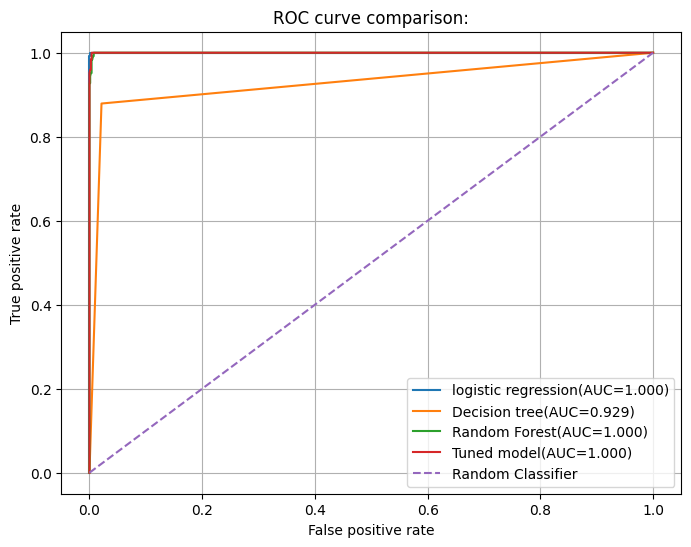

In [51]:
#Roc curve:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
models={'logistic regression':lr_model,
        'Decision tree':dt_model,
        'Random Forest':rf_model,
        'Tuned model':grid_search.best_estimator_}
plt.figure(figsize=(8,6))
for name,model in models.items():
  y_prob= model.predict_proba(x_testf)[:,1]
  fpr,tpr,thresholds= roc_curve(y_test,y_prob)
  auc= roc_auc_score(y_test,y_prob)
  plt.plot(fpr,tpr,label=f'{name}(AUC={auc:.3f})')

plt.plot([0,1],[0,1],linestyle='--',label='Random Classifier')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve comparison:')
plt.legend()
plt.grid()
plt.show()

ROC (Receiver Operating Characteristic) curve evaluates a classification model by comparing:
- TPR (True Positive Rate): Correctly identified high-risk customers.
- FPR (False Positive Rate): Low-risk customers incorrectly classified as high-risk.

The closer the curve is to the top-left corner, the better the model.

Higher AUC means better ability to distinguish between low-risk and high-risk customers.

In [53]:
#compare auc-roc score:
from sklearn.metrics import roc_auc_score
models={'logistic regression':lr_model,
        'Decision tree':dt_model,
        'Random Forest':rf_model,
        'Tuned model':grid_search.best_estimator_}
auc_results=[]
for name,model in models.items():
  y_prob= model.predict_proba(x_testf)[:,1]
  auc= roc_auc_score(y_test,y_prob)
  auc_results.append({'model':name,'auc-roc score':auc})

auc_df= pd.DataFrame(auc_results)
print(auc_df)

                 model  auc-roc score
0  logistic regression       0.999990
1        Decision tree       0.928838
2        Random Forest       0.999737
3          Tuned model       0.999873


In [55]:
#best final model:
models={'logistic regression':lr_model,
        'Decision tree':dt_model,
        'Random Forest':rf_model,
        'Tuned model':grid_search.best_estimator_}
results=[]
for name,model in models.items():
  y_pred=model.predict(x_testf)
  tn,fp,fn,tp=confusion_matrix(y_test,y_pred).ravel()
  recall=recall_score(y_test,y_pred)
  results.append({'model':name,'False Negatives':fn,'recall':recall})
results_df=pd.DataFrame(results)
print(results_df.sort_values(by='False Negatives'))

                 model  False Negatives    recall
0  logistic regression                0  1.000000
2        Random Forest                7  0.943548
3          Tuned model                7  0.943548
1        Decision tree               15  0.879032


In [57]:
best_model_name=results_df.loc[results_df['False Negatives'].idxmin(),'model']
print("Best Final model:",best_model_name)

Best Final model: logistic regression


Therefore among the four models which are logistic regression, random forest, decision tree and tuned random forest , The best model is logistic regression based on business requiredments (minimizing false negatives).

#Part H- Final anaylsis and report:

#best classification model:
After evaluating different classification models, Logistic Regression was selected as the best-performing model for the Credit Risk Classification problem.

The Logistic Regression model achieved an accuracy of 99.89%, precision of 99.20%, recall of 100%, and an F1-score of 99.60%. Its AUC-ROC score was approximately 0.99999, indicating excellent classification performance.

#Impact of imbalance handing techniques:

Class imbalance occurs when one class has significantly more observations than another class. It can affect the performance of machine learning models, especially when predicting the minority class.

To understand its impact, different class-balancing techniques were applied to the training dataset.

Under-Sampling: This technique reduces the number of majority-class observations to balance the dataset. It achieved 100% recall but reduced the F1-score to approximately 95.75%.

Over-Sampling: This technique increases the number of minority-class observations by duplicating existing samples. It achieved 100% recall and an F1-score of approximately 96.50%.

SMOTE: Synthetic Minority Over-sampling Technique generates artificial minority-class samples using existing observations. It achieved 100% recall and an F1-score of approximately 98.02%.

ADASYN: This technique generates synthetic samples by focusing more on minority-class observations that are difficult to classify. It achieved 100% recall and an F1-score of approximately 95.75%.

The original Logistic Regression model achieved the highest F1-score of approximately 99.60% and an AUC-ROC score of approximately 0.99999.

#comparison of Performance metrics:
Different classification models, including Logistic Regression, Decision Tree, Random Forest, and the Tuned Model, were evaluated to identify the most suitable model.

The AUC-ROC scores showed that Logistic Regression achieved the highest score of 0.999990, followed by the Tuned Model with 0.999873 and Random Forest with 0.999737. Decision Tree achieved an AUC-ROC score of 0.928838.


The False Negative and Recall results provided further insight into model performance.


Logistic Regression: Achieved 100% recall with zero false negatives, correctly identifying all high-risk customers.


Decision Tree: Achieved 87.90% recall with 15 false negatives, indicating that some high-risk customers were incorrectly classified as low-risk.


Random Forest: Achieved 94.35% recall with 7 false negatives.


Tuned Model: Achieved 94.35% recall with 7 false negatives.


These results indicate that Logistic Regression performed best in identifying high-risk customers. Although Random Forest and the Tuned Model achieved high AUC-ROC scores, they produced more false negatives than Logistic Regression.


Overall, Logistic Regression demonstrated the strongest performance based on AUC-ROC, Recall, and False Negative results.

#business interpretation of false positive and false negatives:
In credit risk classification, prediction errors can directly affect financial decisions and business operations.

##False Positive (Type-I Error):

A false positive occurs when an actual low-risk customer is incorrectly predicted as high-risk.

Business impact:

1.Genuine customers may face unnecessary restrictions.

2.Loan applications may be rejected unnecessarily.

3.Customer satisfaction and trust may decrease.

In our Logistic Regression model, only one false positive was observed.

##False Negative (Type-II Error):

A false negative occurs when an actual high-risk customer is incorrectly predicted as low-risk.

Business impact:

1.Banks may approve loans to risky customers.

2.The possibility of loan defaults increases.

3.Financial losses may occur.

Our Logistic Regression model produced zero false negatives, meaning that all actual high-risk customers in the test dataset were correctly identified.